# Gene annotation and expression plots

This notebook uses the precomputed limma–voom results for symptomatic versus asymptomatic malaria and the aligned bulk PBMC count matrix. Run the cells from top to bottom. Plots are saved in the project's `results/figures` directory.

If packages are missing, run `%pip install numpy pandas matplotlib seaborn scipy scikit-learn mygene` in a notebook cell. The final annotation section uses MyGene.info and requires internet access.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.patches import Patch
from scipy.spatial.distance import pdist, squareform
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

PROJECT_DIR = Path("/workspaces/Malaria-host-response-systems")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
FIGURES_DIR = PROJECT_DIR / "results" / "figures"

COHORT_COLOURS = {
    "Healthy": "green",
    "Asymptomatic": "blue",
    "Symptomatic": "red",
}
COHORT_LABELS = {
    "Healthy": "Healthy controls",
    "Asymptomatic": "Asymptomatic malaria",
    "Symptomatic": "Symptomatic malaria",
}

## 1. Load and align inputs

The metadata index determines the sample order. Gene IDs are treated as text in the expression and differential-expression tables so they can be matched directly.

In [3]:
limma_results = pd.read_csv(
    PROCESSED_DIR / "limma_voom_symptomatic_vs_asymptomatic.csv",
    dtype={"GeneID": str},
)
count_table = pd.read_csv(
    PROCESSED_DIR / "count_matrix_integer.txt", sep="\t", dtype=str
)
counts_full = count_table.set_index(count_table.columns[0])
metadata = pd.read_csv(PROCESSED_DIR / "sample_metadata_aligned.csv", dtype=str)
metadata = metadata.set_index(metadata.columns[0])

if not metadata.index.is_unique:
    raise ValueError("Sample metadata contains duplicate sample IDs.")
if not counts_full.index.is_unique or not limma_results["GeneID"].is_unique:
    raise ValueError("Each count and limma–voom table must have unique gene IDs.")
if counts_full.index.hasnans or limma_results["GeneID"].isna().any():
    raise ValueError("The count or limma–voom table contains missing gene IDs.")

missing_samples = metadata.index.difference(counts_full.columns)
if len(missing_samples):
    raise ValueError(f"Samples missing from the count matrix: {missing_samples.tolist()}")

cohort = metadata["group"]
if not cohort.isin(COHORT_COLOURS).all():
    raise ValueError("Metadata group labels must be Healthy, Asymptomatic or Symptomatic.")

counts_full = counts_full.loc[:, metadata.index].apply(pd.to_numeric)
if not np.isfinite(counts_full.to_numpy()).all() or counts_full.lt(0).any().any():
    raise ValueError("Counts must be finite and nonnegative.")

limma_results["adj.P.Val"] = pd.to_numeric(limma_results["adj.P.Val"])
ranked_results = limma_results.sort_values("adj.P.Val").dropna(subset=["adj.P.Val"])

## 2. Filter counts and calculate expression

Retain genes with at least 0.5 CPM in at least five samples. For the plots, recalculate CPM using each sample's total in the filtered count matrix, then apply $\log_2(\mathrm{CPM}+1)$.

In [4]:
library_sizes = counts_full.sum(axis=0)
if library_sizes.le(0).any():
    raise ValueError("Each sample must have a positive library size.")

cpm = counts_full.div(library_sizes, axis=1) * 1e6
counts_filt = counts_full.loc[(cpm >= 0.5).sum(axis=1) >= 5]
filtered_sizes = counts_filt.sum(axis=0)
if len(counts_filt) < 2 or filtered_sizes.le(0).any():
    raise ValueError("The CPM filter left too few genes or a sample with no counts.")

log2cpm = np.log2(counts_filt.div(filtered_sizes, axis=1) * 1e6 + 1)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print(f"Retained {log2cpm.shape[0]:,} genes across {log2cpm.shape[1]} samples.")

Retained 16,110 genes across 17 samples.


## 3. Poster heatmap

Select the first 50 genes ranked by increasing Benjamini–Hochberg-adjusted $P$ value (`adj.P.Val`) in the symptomatic-versus-asymptomatic contrast. Display the selected genes that occur in the filtered expression matrix across all aligned samples, including healthy controls. Rows and columns are clustered by average linkage using Euclidean distance. Colour intensity shows $\log_2(\mathrm{CPM}+1)$.

Displayed 50 of 50 selected genes.


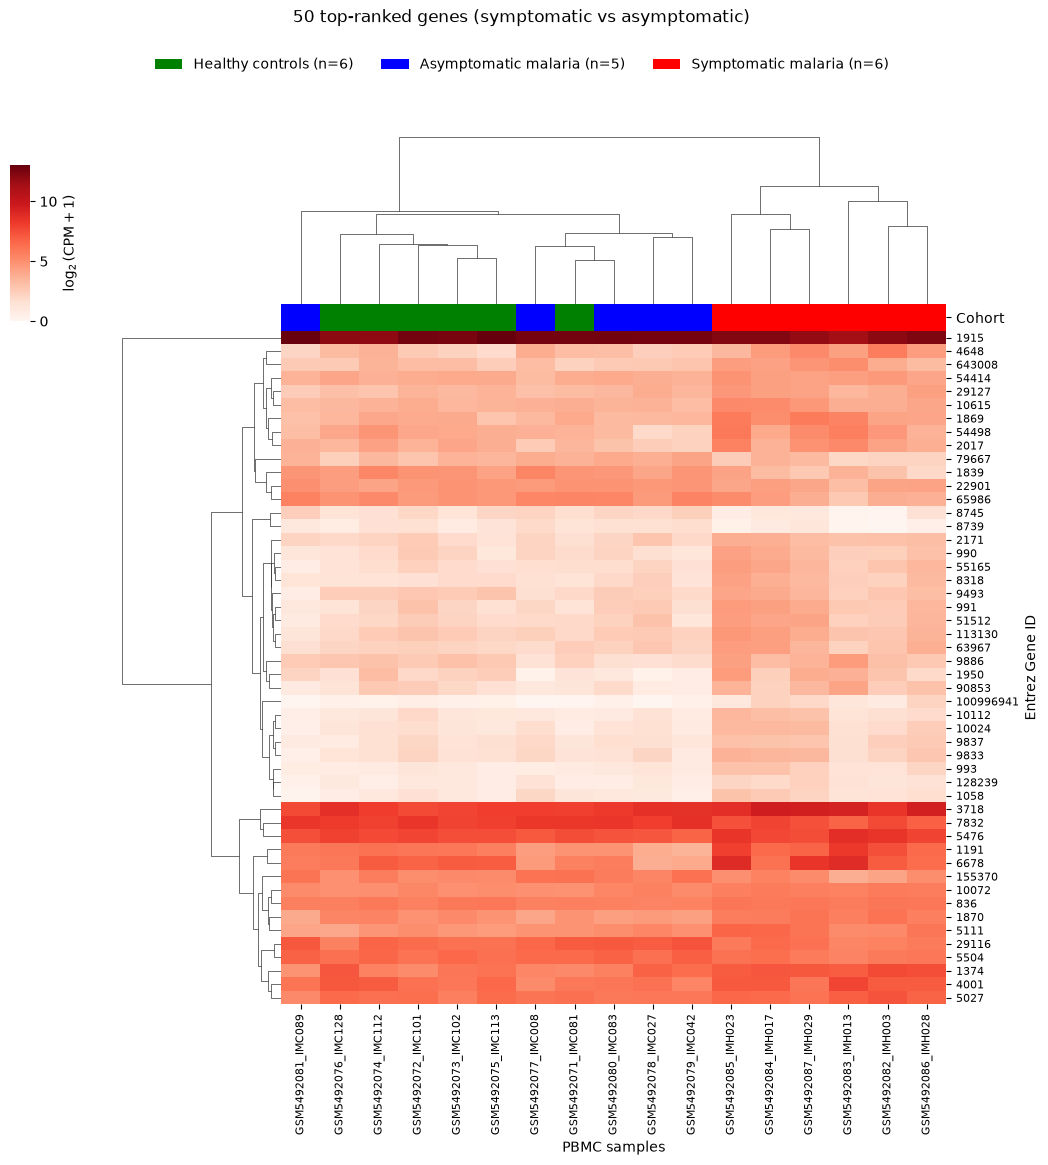

In [5]:
top50_ids = ranked_results.head(50)["GeneID"].tolist()
valid_ids = [gene_id for gene_id in top50_ids if gene_id in log2cpm.index]
if len(valid_ids) < 2:
    raise ValueError("Fewer than two ranked genes match the filtered expression matrix.")

top50_expr = log2cpm.loc[valid_ids]
heatmap_cohort = cohort.loc[top50_expr.columns]
cluster = sns.clustermap(
    top50_expr,
    method="average",
    metric="euclidean",
    cmap="Reds",
    col_colors=heatmap_cohort.map(COHORT_COLOURS).rename("Cohort"),
    figsize=(11, 12),
    yticklabels=True,
    xticklabels=True,
    cbar_kws={"label": r"$\log_2(\mathrm{CPM}+1)$"},
)
cluster.fig.subplots_adjust(left=0.13, top=0.88)
cluster.ax_cbar.set_position([0.035, 0.72, 0.018, 0.13])
cluster.fig.suptitle(
    f"{len(valid_ids)} top-ranked genes (symptomatic vs asymptomatic)", y=0.98
)

cohort_legend = [
    Patch(
        facecolor=colour,
        label=f"{COHORT_LABELS[group]} (n={heatmap_cohort.eq(group).sum()})",
    )
    for group, colour in COHORT_COLOURS.items()
]
cluster.fig.legend(
    handles=cohort_legend,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.95),
    ncol=3,
    frameon=False,
)
cluster.ax_heatmap.set_xlabel("PBMC samples")
cluster.ax_heatmap.set_ylabel("Entrez Gene ID")
cluster.ax_heatmap.tick_params(axis="both", labelsize=8)

cluster.savefig(FIGURES_DIR / "heatmap_top50_sm_vs_am.png", dpi=300)
print(f"Displayed {len(valid_ids)} of {len(top50_ids)} selected genes.")
plt.show()

## 4. Principal component analysis

Standardise each gene across samples before calculating the first two principal components. Axis labels give the percentage of variance explained.

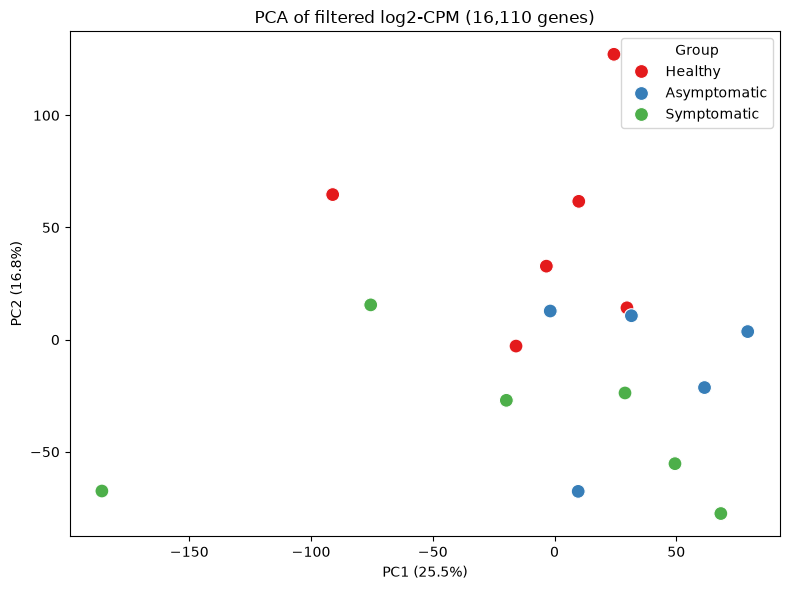

In [6]:
scaled_expression = StandardScaler().fit_transform(log2cpm.T)
pca = PCA(n_components=2)
pca_df = pd.DataFrame(
    pca.fit_transform(scaled_expression),
    index=log2cpm.columns,
    columns=["PC1", "PC2"],
).join(metadata[["group"]])

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(
    data=pca_df, x="PC1", y="PC2", hue="group", s=100,
    palette="Set1", ax=ax,
)
ax.set_title(f"PCA of filtered log2-CPM ({len(counts_filt):,} genes)")
ax.set_xlabel(f"PC1 ({100*pca.explained_variance_ratio_[0]:.1f}%)")
ax.set_ylabel(f"PC2 ({100*pca.explained_variance_ratio_[1]:.1f}%)")
ax.legend(title="Group")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "PCA_limma_filtered.png", dpi=150)
plt.show()

## 5. Sample distances

Calculate Euclidean distances between samples using the filtered log-transformed expression matrix.

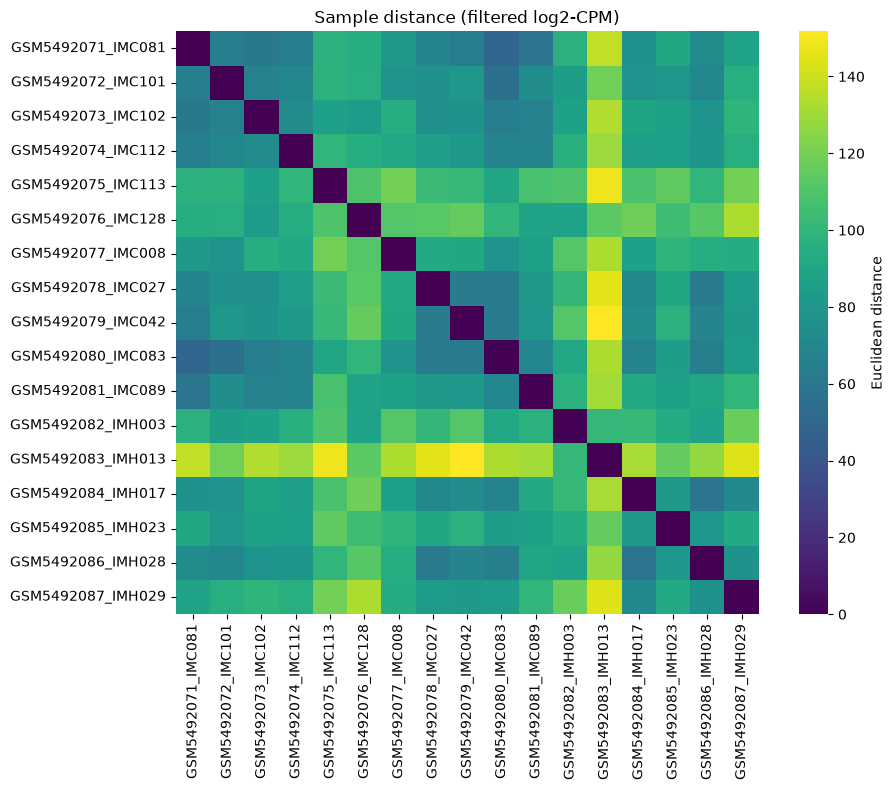

In [7]:
distances = squareform(pdist(log2cpm.T, metric="euclidean"))
distance_df = pd.DataFrame(
    distances, index=log2cpm.columns, columns=log2cpm.columns
)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    distance_df, cmap="viridis", square=True,
    cbar_kws={"label": "Euclidean distance"}, ax=ax,
)
ax.set_title("Sample distance (filtered log2-CPM)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "sample_distance_heatmap.png", dpi=150)
plt.show()

## 6. Annotate genes and review the contrast

Retrieve human gene symbols for the Entrez IDs using MyGene.info. The candidate table includes `SIRT1`, `SMAD7` and `CTLA4` so their estimated expression differences and adjusted $P$ values can be inspected alongside the original genes of interest.

In [8]:
import mygene

gene_info = mygene.MyGeneInfo().querymany(
    limma_results["GeneID"].tolist(),
    scopes="entrezgene",
    fields="symbol",
    species="human",
    verbose=False,
)
id_to_symbol = {
    str(entry["query"]): entry["symbol"]
    for entry in gene_info
    if entry.get("symbol")
}

annotated_results = limma_results.assign(
    Symbol=limma_results["GeneID"].map(id_to_symbol)
)
annotated_results.to_csv(
    PROCESSED_DIR / "limma_voom_symptomatic_vs_asymptomatic_with_symbols.csv",
    index=False,
)

top20_columns = ["GeneID", "Symbol", "logFC", "AveExpr", "adj.P.Val"]
print(f"Genes with adjusted P < 0.05: {ranked_results['adj.P.Val'].lt(0.05).sum()}")
display(annotated_results.loc[ranked_results.index[:20], top20_columns])

genes_of_interest = [
    "IFNG", "CXCL9", "SLAMF7", "LAG3", "CTLA4",
    "BTG1", "IRF2BP2", "NR1D1", "SIRT1", "SMAD7",
]
candidate_rows = annotated_results["Symbol"].isin(genes_of_interest)
display(annotated_results.loc[candidate_rows, ["Symbol", "logFC", "adj.P.Val", "GeneID"]])

Genes with adjusted P < 0.05: 2


,GeneID,Symbol,logFC,AveExpr,adj.P.Val
891,1870,E2F2,1.708635,5.152966,0.000255
603,1191,CLU,2.974810,5.945431,0.026834
8070,55165,CEP55,2.382853,1.970288,0.056430
14875,100996941,IL21-AS1,4.208965,-1.366450,0.056430
4057,8745,ADAM23,-2.791441,0.736052,0.076174
7670,54414,SIAE,0.866245,3.998982,0.090368
11100,113130,CDCA5,1.756169,2.605510,0.090368
4720,9837,GINS1,1.597989,1.396692,0.090368
7711,54498,SMOX,2.389022,3.926095,0.090368
3698,7832,BTG2,-0.973413,7.975118,0.090368


,Symbol,logFC,adj.P.Val,GeneID
337,BTG1,-0.633635,0.144943,694
729,CTLA4,0.760037,0.333871,1493
1554,IFNG,0.562503,0.679875,3458
1746,LAG3,1.613822,0.138969,3902
1846,SMAD7,-1.117654,0.090368,4092
1933,CXCL9,3.053346,0.130392,4283
4523,NR1D1,-1.394891,0.175011,9572
6137,SIRT1,-0.605431,0.128742,23411
9012,SLAMF7,1.054266,0.151530,57823
13209,IRF2BP2,-0.666465,0.147957,359948
